In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (BaggingClassifier, RandomForestClassifier, ExtraTreesClassifier,
                              AdaBoostClassifier, HistGradientBoostingClassifier)

RANDOM_STATE = 42
LABELS = {1: "Fatal", 2: "Serious", 3: "Slight"}

In [3]:
CSV_COLLISION = "dft-road-casualty-statistics-collision-1979-latest-published-year.csv"
CSV_VEHICLE   = "dft-road-casualty-statistics-vehicle-1979-latest-published-year.csv"
CSV_CASUALTY  = "dft-road-casualty-statistics-casualty-1979-latest-published-year.csv"

MIN_YEAR = 2019


def read_filtered(path, cols, keep_ids=None, min_year=None):
    parts = []
    for chunk in pd.read_csv(path, usecols=cols, chunksize=500_000):
        if min_year is not None:
            chunk = chunk[chunk["collision_year"] >= min_year]
        if keep_ids is not None:
            chunk = chunk[chunk["collision_index"].isin(keep_ids)]
        parts.append(chunk)
    return pd.concat(parts, ignore_index=True)

In [4]:
collision_cols = [
    "collision_index", "collision_year", "collision_severity", "number_of_vehicles",
    "date", "day_of_week", "time", "first_road_class", "road_type", "speed_limit",
    "junction_detail", "junction_control", "pedestrian_crossing", "light_conditions",
    "weather_conditions", "road_surface_conditions", "urban_or_rural_area", "trunk_road_flag",
]

collisions = read_filtered(CSV_COLLISION, collision_cols, min_year=MIN_YEAR)
keep_ids = set(collisions["collision_index"])
print(collisions.shape)

(722536, 18)


In [5]:
vehicles = read_filtered(CSV_VEHICLE, ["collision_index", "vehicle_type", "age_of_driver"], keep_ids)

vehicles["age_of_driver"] = vehicles["age_of_driver"].where(vehicles["age_of_driver"] >= 0)  # -1 means missing

# flag each vehicle type, then add them up per collision
vt = vehicles["vehicle_type"]
vehicles["n_motorcycles"] = vt.isin([2, 3, 4, 5, 23, 97]).astype(int)
vehicles["n_cars"]        = (vt == 9).astype(int)
vehicles["n_vans"]        = (vt == 19).astype(int)
vehicles["n_hgv"]         = vt.isin([20, 21, 98]).astype(int)
vehicles["n_buses"]       = vt.isin([10, 11]).astype(int)
vehicles["n_cyclists"]    = (vt == 1).astype(int)

vehicle_summary = vehicles.groupby("collision_index").agg(
    n_motorcycles=("n_motorcycles", "sum"),
    n_cars=("n_cars", "sum"),
    n_vans=("n_vans", "sum"),
    n_hgv=("n_hgv", "sum"),
    n_buses=("n_buses", "sum"),
    n_cyclists=("n_cyclists", "sum"),
    youngest_driver=("age_of_driver", "min"),
    oldest_driver=("age_of_driver", "max"),
).reset_index()
print(vehicle_summary.shape)

(722536, 9)


In [6]:
casualty_cols = ["collision_index", "casualty_class", "sex_of_casualty", "age_of_casualty"]
casualties = read_filtered(CSV_CASUALTY, casualty_cols, keep_ids)

casualties["age_of_casualty"] = casualties["age_of_casualty"].where(casualties["age_of_casualty"] >= 0)

casualties["is_pedestrian"] = (casualties["casualty_class"] == 3).astype(int)
casualties["is_male"]       = (casualties["sex_of_casualty"] == 1).astype(int)
casualties["is_female"]     = (casualties["sex_of_casualty"] == 2).astype(int)
casualties["is_child"]      = ((casualties["age_of_casualty"] < 16) & casualties["age_of_casualty"].notna()).astype(int)

casualty_summary = casualties.groupby("collision_index").agg(
    n_casualties=("casualty_class", "size"),
    n_pedestrian_casualties=("is_pedestrian", "sum"),
    n_male_casualties=("is_male", "sum"),
    n_female_casualties=("is_female", "sum"),
    n_child_casualties=("is_child", "sum"),
    youngest_casualty=("age_of_casualty", "min"),
    oldest_casualty=("age_of_casualty", "max"),
).reset_index()
print(casualty_summary.shape)

CASUALTY_FEATURES = [c for c in casualty_summary.columns if c != "collision_index"]

(722536, 8)


In [7]:
df = collisions.merge(vehicle_summary, on="collision_index", how="left")
df = df.merge(casualty_summary, on="collision_index", how="left")

print(df.shape)
assert len(df) == len(collisions)

(722536, 33)


In [8]:
cols_to_clean = [c for c in df.columns if c != "junction_control"]
df[cols_to_clean] = df[cols_to_clean].replace(-1, np.nan)

for col in ["junction_detail", "pedestrian_crossing"]:
    df[col] = df[col].replace(99, np.nan)

(df.isna().mean() * 100).sort_values(ascending=False).head(10)

trunk_road_flag            7.339288
oldest_driver              5.164033
youngest_driver            5.164033
pedestrian_crossing        3.948731
junction_detail            3.365645
youngest_casualty          1.578745
oldest_casualty            1.578745
road_surface_conditions    0.573259
speed_limit                0.013148
light_conditions           0.004982
dtype: float64

In [9]:
df["hour"]         = pd.to_datetime(df["time"], format="%H:%M", errors="coerce").dt.hour
df["month"]        = pd.to_datetime(df["date"], format="%d/%m/%Y", errors="coerce").dt.month
df["is_weekend"]   = df["day_of_week"].isin([1, 7]).astype(int)      # 1 = Sunday, 7 = Saturday
RUSH_HOURS = [7, 8, 9, 16, 17, 18]
df["is_rush_hour"] = df["hour"].isin(RUSH_HOURS).astype(int)

df = df.drop(columns=["date", "time"])
df.shape

(722536, 35)

collision_severity
3    0.766
2    0.219
1    0.015
Name: proportion, dtype: float64


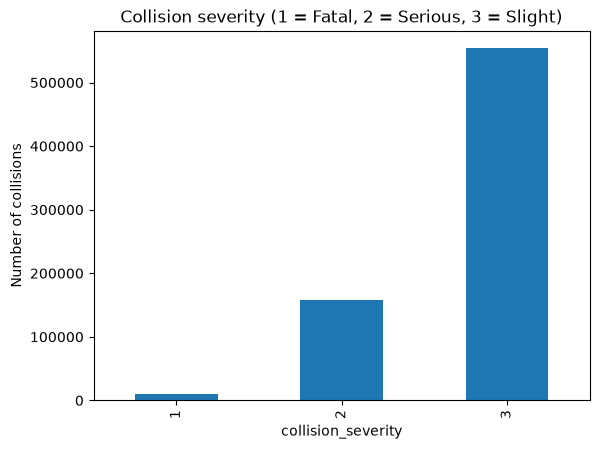

In [10]:
print(df["collision_severity"].value_counts(normalize=True).round(3))

df["collision_severity"].value_counts().sort_index().plot(kind="bar")
plt.title("Collision severity (1 = Fatal, 2 = Serious, 3 = Slight)")
plt.ylabel("Number of collisions")
plt.show()

In [11]:
# The headline accuracy score is optimized for the dominant 'Slight' class.
# Keep all post-collision casualty outcomes out of the predictor (target leakage).
USE_CASUALTY_FEATURES = False

y = df["collision_severity"]
drop_cols = ["collision_severity", "collision_index", "collision_year"]
if not USE_CASUALTY_FEATURES:
    drop_cols += CASUALTY_FEATURES
X = df.drop(columns=drop_cols)

# the tree models used here need numeric, NaN-free input, so fill with -1
X = X.fillna(-1)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(X_train.shape, X_test.shape)

(578028, 25) (144508, 25)


In [12]:
X_small = X_train.sample(200_000, random_state=RANDOM_STATE)
y_small = y_train.loc[X_small.index]

def tree(depth, **kw):
    return DecisionTreeClassifier(max_depth=depth, class_weight="balanced", random_state=RANDOM_STATE, **kw)

models = {
    "Decision Tree (baseline)": tree(10),
    # Accuracy-focused model: do not rebalance classes when overall accuracy is the goal.
    "Bagging (accuracy)":       BaggingClassifier(estimator=DecisionTreeClassifier(max_depth=15, min_samples_leaf=20, random_state=RANDOM_STATE), n_estimators=30,n_jobs=1, random_state=RANDOM_STATE),
    "Random Forest (balanced)": RandomForestClassifier(n_estimators=100, max_depth=15, min_samples_leaf=20,class_weight="balanced", n_jobs=2, random_state=RANDOM_STATE),
    "Extra Trees (balanced)":   ExtraTreesClassifier(n_estimators=100, max_depth=15, min_samples_leaf=20,class_weight="balanced", n_jobs=2, random_state=RANDOM_STATE),
    "AdaBoost (accuracy)":      AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=2, random_state=RANDOM_STATE), n_estimators=100, random_state=RANDOM_STATE),
    "Hist Gradient Boosting":   HistGradientBoostingClassifier(max_iter=200, class_weight="balanced",random_state=RANDOM_STATE),
}

results = []
trained = {}
predictions = {}

for name, model in models.items():
    print("Training", name, "...")
    model.fit(X_small, y_small)
    pred = model.predict(X_test)

    trained[name] = model
    predictions[name] = pred
    results.append({
        "model": name,
        "accuracy": round(accuracy_score(y_test, pred), 3),
        "macro_f1": round(f1_score(y_test, pred, average="macro"), 3),
    })

results_df = pd.DataFrame(results)
results_df["accuracy_lift_vs_majority"] = results_df["accuracy"] - y_test.value_counts(normalize=True).max()
results_df_macro_f1 = results_df.sort_values("macro_f1", ascending=False).reset_index(drop=True)
results_df_macro_f1

Training Decision Tree (baseline) ...
Training Bagging (accuracy) ...
Training Random Forest (balanced) ...
Training Extra Trees (balanced) ...
Training AdaBoost (accuracy) ...
Training Hist Gradient Boosting ...


,model,accuracy,macro_f1,accuracy_lift_vs_majority
0,Random Forest (balanced),0.549,0.384,-0.217449
1,Extra Trees (balanced),0.569,0.381,-0.197449
2,Hist Gradient Boosting,0.538,0.375,-0.228449
3,Decision Tree (baseline),0.495,0.349,-0.271449
4,AdaBoost (accuracy),0.768,0.338,0.001551
5,Bagging (accuracy),0.771,0.335,0.004551


In [13]:
results_df_accuracy_score = results_df.sort_values("accuracy", ascending=False).reset_index(drop=True)
results_df_accuracy_score

,model,accuracy,macro_f1,accuracy_lift_vs_majority
0,Bagging (accuracy),0.771,0.335,0.004551
1,AdaBoost (accuracy),0.768,0.338,0.001551
2,Extra Trees (balanced),0.569,0.381,-0.197449
3,Random Forest (balanced),0.549,0.384,-0.217449
4,Hist Gradient Boosting,0.538,0.375,-0.228449
5,Decision Tree (baseline),0.495,0.349,-0.271449


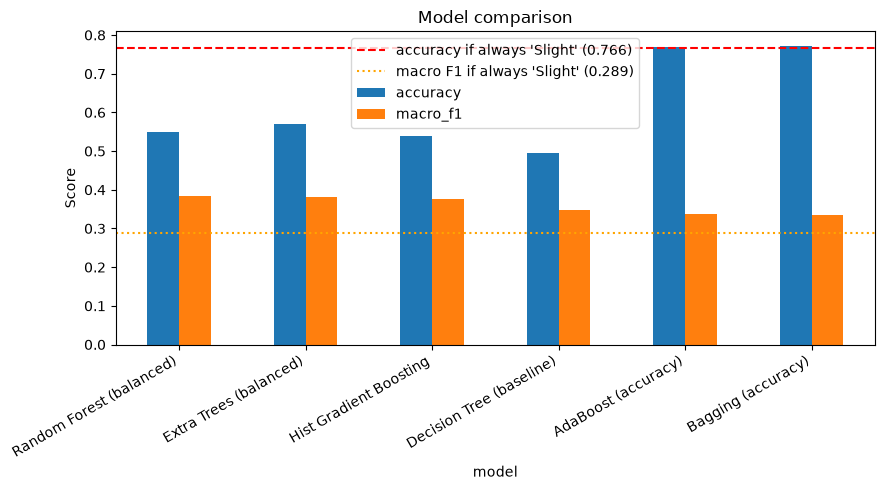

In [14]:
majority_pred = np.full(len(y_test), 3)
base_acc = accuracy_score(y_test, majority_pred)
base_f1  = f1_score(y_test, majority_pred, average="macro")

ax = results_df_macro_f1.set_index("model")[["accuracy", "macro_f1"]].plot(kind="bar", figsize=(9, 5))
ax.axhline(base_acc, color="red",    linestyle="--", label=f"accuracy if always 'Slight' ({base_acc:.3f})")
ax.axhline(base_f1,  color="orange", linestyle=":",  label=f"macro F1 if always 'Slight' ({base_f1:.3f})")
plt.title("Model comparison")
plt.ylabel("Score")
plt.xticks(rotation=30, ha="right")
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
best_f1_name  = results_df_macro_f1.loc[0, "model"]
best_f1_model = trained[best_f1_name]
best_f1_pred  = predictions[best_f1_name]
print("Best model (by macro F1):", best_f1_name)
print(classification_report(y_test, best_f1_pred, target_names=list(LABELS.values())))

best_acc_name  = results_df_accuracy_score.loc[0, "model"]
best_acc_model = trained[best_acc_name]
best_acc_pred  = predictions[best_acc_name]
print("Best model (by accuracy):", best_acc_name)
print(classification_report(y_test, best_acc_pred, target_names=list(LABELS.values())))

Best model (by macro F1): Random Forest (balanced)
              precision    recall  f1-score   support

       Fatal       0.05      0.54      0.10      2120
     Serious       0.30      0.47      0.37     31630
      Slight       0.86      0.57      0.69    110758

    accuracy                           0.55    144508
   macro avg       0.41      0.53      0.38    144508
weighted avg       0.73      0.55      0.61    144508

Best model (by accuracy): Bagging (accuracy)
              precision    recall  f1-score   support

       Fatal       0.00      0.00      0.00      2120
     Serious       0.54      0.08      0.14     31630
      Slight       0.78      0.98      0.87    110758

    accuracy                           0.77    144508
   macro avg       0.44      0.35      0.34    144508
weighted avg       0.72      0.77      0.70    144508



c:\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Python314\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


[[ 1141   687   292]
 [ 6855 14951  9824]
 [13388 34081 63289]]


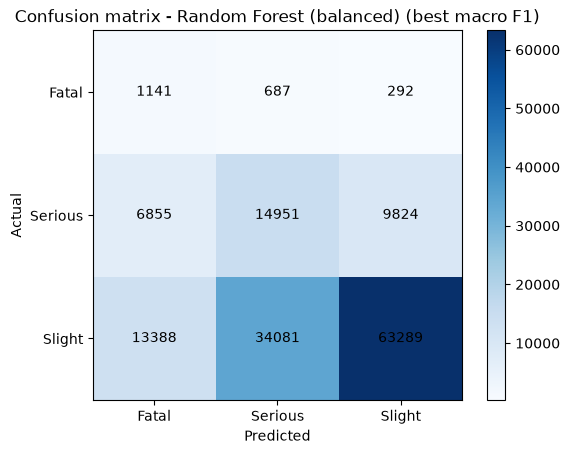

[[     0    290   1830]
 [     0   2470  29160]
 [     0   1795 108963]]


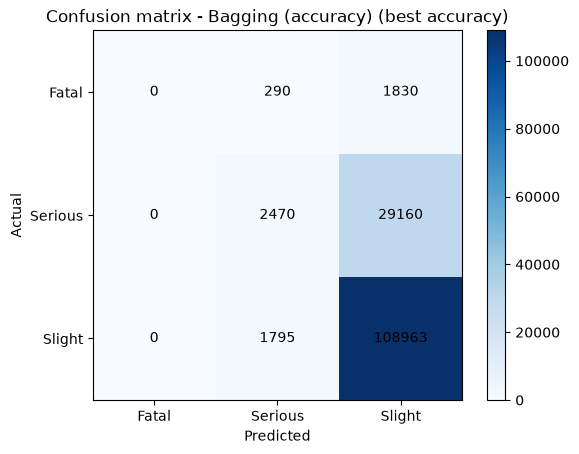

In [16]:
def plot_confusion(y_true, pred, title):
    cm = confusion_matrix(y_true, pred)
    print(cm)
    plt.figure()
    plt.imshow(cm, cmap="Blues")
    plt.colorbar()
    plt.xticks([0, 1, 2], list(LABELS.values()))
    plt.yticks([0, 1, 2], list(LABELS.values()))
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(title)
    for i in range(3):
        for j in range(3):
            plt.text(j, i, cm[i, j], ha="center", va="center")
    plt.show()

plot_confusion(y_test, best_f1_pred,  "Confusion matrix - " + best_f1_name + " (best macro F1)")
plot_confusion(y_test, best_acc_pred, "Confusion matrix - " + best_acc_name + " (best accuracy)")

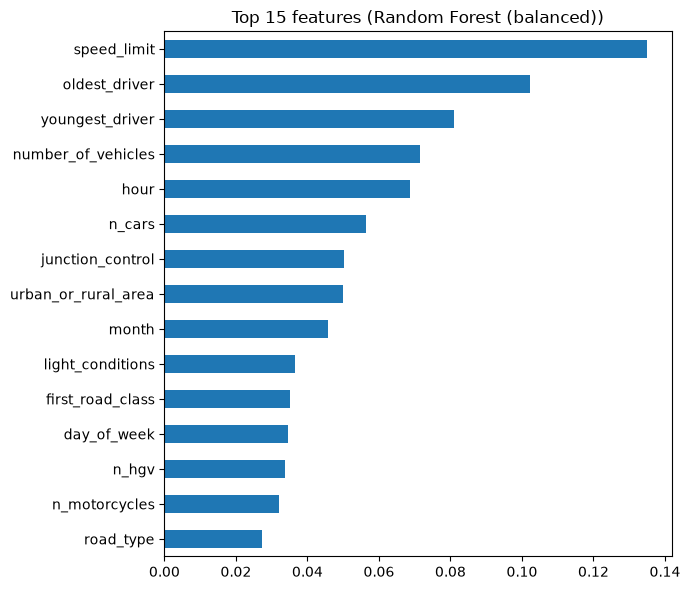

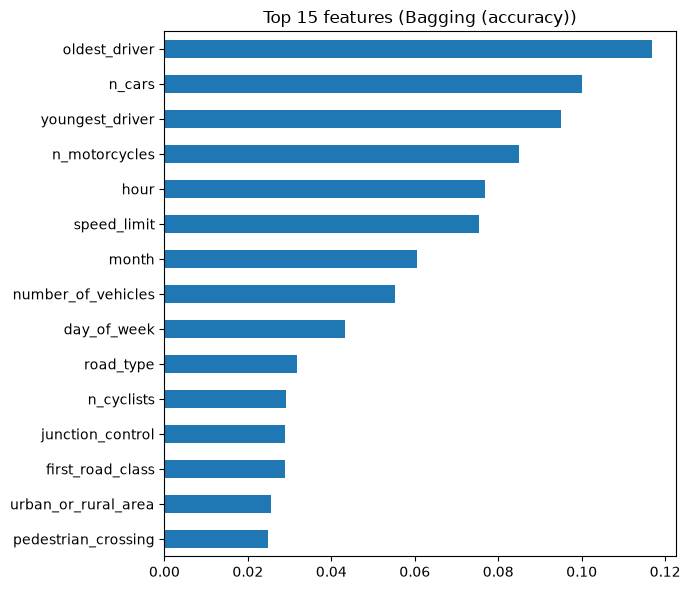

In [17]:
def get_importances(model, columns):
    if hasattr(model, "feature_importances_"):
        values = model.feature_importances_
    elif hasattr(model, "estimators_"):
        values = np.mean([est.feature_importances_ for est in model.estimators_], axis=0)
    else:
        return None
    return pd.Series(values, index=columns).sort_values(ascending=False)

for name in ["Random Forest (balanced)", "Bagging (accuracy)"]:
    imp = get_importances(trained[name], X.columns)
    imp.head(15).sort_values().plot(kind="barh", figsize=(7, 6))
    plt.title(f"Top 15 features ({name})")
    plt.tight_layout()
    plt.show()

In [18]:
sample = X_test.sample(10, random_state=1)
check = pd.DataFrame({
    "actual":    y_test.loc[sample.index].map(LABELS),
    "predicted": pd.Series(best_f1_model.predict(sample), index=sample.index).map(LABELS),
})
check

,actual,predicted
580045,Slight,Serious
721010,Slight,Serious
288549,Slight,Slight
524286,Slight,Slight
326177,Slight,Slight
698857,Serious,Serious
455168,Slight,Fatal
668769,Serious,Slight
226123,Slight,Slight
495548,Slight,Serious


In [19]:
new_accident = X.median().to_frame().T

new_accident["speed_limit"]         = 50
new_accident["number_of_vehicles"]  = 2
new_accident["n_motorcycles"]       = 1
new_accident["n_cars"]              = 1
new_accident["light_conditions"]    = 6      # 6 = darkness, no street lighting (1 = daylight)
new_accident["hour"]                = 23
new_accident["is_rush_hour"]        = int(23 in RUSH_HOURS)
new_accident["urban_or_rural_area"] = 2      # 2 = rural

pred = best_f1_model.predict(new_accident)[0]
print("Model:", best_f1_name)
print("Predicted severity:", LABELS[pred])

probs = best_f1_model.predict_proba(new_accident)[0]
for cls, p in zip(best_f1_model.classes_, probs):
    print(LABELS[cls], round(p, 3))

Model: Random Forest (balanced)
Predicted severity: Fatal
Fatal 0.432
Serious 0.354
Slight 0.213


In [20]:
# cross-validate the model chosen above (stratified + shuffled, since the classes are imbalanced)
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
scores = cross_val_score(best_f1_model, X_small, y_small, cv=cv, scoring="f1_macro")
print(best_f1_name, scores.round(3), "average:", scores.mean().round(3))

Random Forest (balanced) [0.386 0.388 0.382] average: 0.385


In [21]:
sample = X_test.sample(10, random_state=1)
check = pd.DataFrame({
    "actual":    y_test.loc[sample.index].map(LABELS),
    "predicted": pd.Series(best_f1_model.predict(sample), index=sample.index).map(LABELS),
})
check

,actual,predicted
580045,Slight,Serious
721010,Slight,Serious
288549,Slight,Slight
524286,Slight,Slight
326177,Slight,Slight
698857,Serious,Serious
455168,Slight,Fatal
668769,Serious,Slight
226123,Slight,Slight
495548,Slight,Serious


In [22]:
sample = X_test.sample(10, random_state=1)
check = pd.DataFrame({
    "actual":    y_test.loc[sample.index].map(LABELS),
    "predicted": pd.Series(best_acc_model.predict(sample), index=sample.index).map(LABELS),
})
check

,actual,predicted
580045,Slight,Slight
721010,Slight,Slight
288549,Slight,Slight
524286,Slight,Slight
326177,Slight,Slight
698857,Serious,Slight
455168,Slight,Slight
668769,Serious,Slight
226123,Slight,Slight
495548,Slight,Slight


In [23]:
# start from the average row so every column has a sensible value
new_accident = X.median().to_frame().T

# change what you want to test (check the DfT guide for what each code means)
new_accident["speed_limit"]        = 50
new_accident["number_of_vehicles"] = 2
new_accident["n_motorcycles"]      = 1
new_accident["n_cars"]             = 1
new_accident["light_conditions"]   = 1    # darkness, no street lights
new_accident["hour"]               = 10
new_accident["urban_or_rural_area"] = 2     # rural

pred = best_acc_model.predict(new_accident)[0]
print("Model (accuracy):", best_acc_name)
print("Predicted severity:", LABELS[pred])

# probability for each class
probs = best_acc_model.predict_proba(new_accident)[0]
for cls, p in zip(best_acc_model.classes_, probs):
    print(LABELS[cls], round(p, 3))

Model (accuracy): Bagging (accuracy)
Predicted severity: Slight
Fatal 0.056
Serious 0.427
Slight 0.517


In [24]:
# start from the average row so every column has a sensible value
new_accident = X.median().to_frame().T

# change what you want to test (check the DfT guide for what each code means)
new_accident["speed_limit"]        = 50
new_accident["number_of_vehicles"] = 2
new_accident["n_motorcycles"]      = 1
new_accident["n_cars"]             = 1
new_accident["light_conditions"]   = 1    # darkness, no street lights
new_accident["hour"]               = 10
new_accident["urban_or_rural_area"] = 2     # rural

pred = best_f1_model.predict(new_accident)[0]
print("Model (macro F1):", best_f1_name)
print("Predicted severity:", LABELS[pred])

# probability for each class
probs = best_f1_model.predict_proba(new_accident)[0]
for cls, p in zip(best_f1_model.classes_, probs):
    print(LABELS[cls], round(p, 3))

Model (macro F1): Random Forest (balanced)
Predicted severity: Serious
Fatal 0.302
Serious 0.451
Slight 0.247


In [ ]:
from sklearn.model_selection import cross_val_score

scores = cross_val_score(best_acc_model, X_small, y_small, cv=cv, scoring="accuracy")
print(best_acc_name, "accuracy CV:", scores.round(3), "average:", scores.mean().round(3))